# 1.  Installation des dépendances

In [3]:
# ==============================
# INSTALLATION
# ==============================
!pip install mtcnn --quiet
!pip install opencv-python-headless --quiet

print("Installation terminée ✅")

Installation terminée ✅


# 2. Imports et configuration

In [4]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch 
from PIL import Image
import warnings
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {device}")

DATASET_PATH = "/kaggle/input/datasets/imaneougni/dataset-faces-detection"
os.makedirs("/kaggle/working/results_mtcnn", exist_ok=True)
print(f"Dataset path : {DATASET_PATH}")

Device : cuda
Dataset path : /kaggle/input/datasets/imaneougni/dataset-faces-detection


# 3. Chargement des images de test

In [5]:
# ==============================
# CHARGEMENT DES IMAGES DE TEST
# ==============================
import glob

extensions = ["*.jpg", "*.jpeg", "*.png",
              "*.JPG", "*.JPEG", "*.PNG"]
all_images = []
for ext in extensions:
    all_images.extend(glob.glob(os.path.join(DATASET_PATH, "**", ext), recursive=True))
    all_images.extend(glob.glob(os.path.join(DATASET_PATH, ext)))

test_paths = sorted(list(set(all_images)))

print(f"Images trouvées : {len(test_paths)}")
for i, p in enumerate(test_paths):
    img = cv2.imread(p)
    h, w = img.shape[:2] if img is not None else (0, 0)
    print(f"  [{i:02d}] {os.path.basename(p):40s} {w}×{h}")

Images trouvées : 15
  [00] Middle_Eastern.JPG                       163×208
  [01] african.JPG                              312×210
  [02] asien.png                                425×232
  [03] caucasien.JPG                            316×213
  [04] cry.JPG                                  247×211
  [05] face_mask.JPG                            374×211
  [06] kids.png                                 226×218
  [07] multifaces.JPG                           279×179
  [08] normale.JPG                              170×188
  [09] old.png                                  417×238
  [10] partially_covered.JPG                    159×208
  [11] sunglasses.JPG                           119×217
  [12] sunlight.JPG                             312×210
  [13] voile.jpg                                230×295
  [14] women.png                                287×234


# 4. Aperçu des images

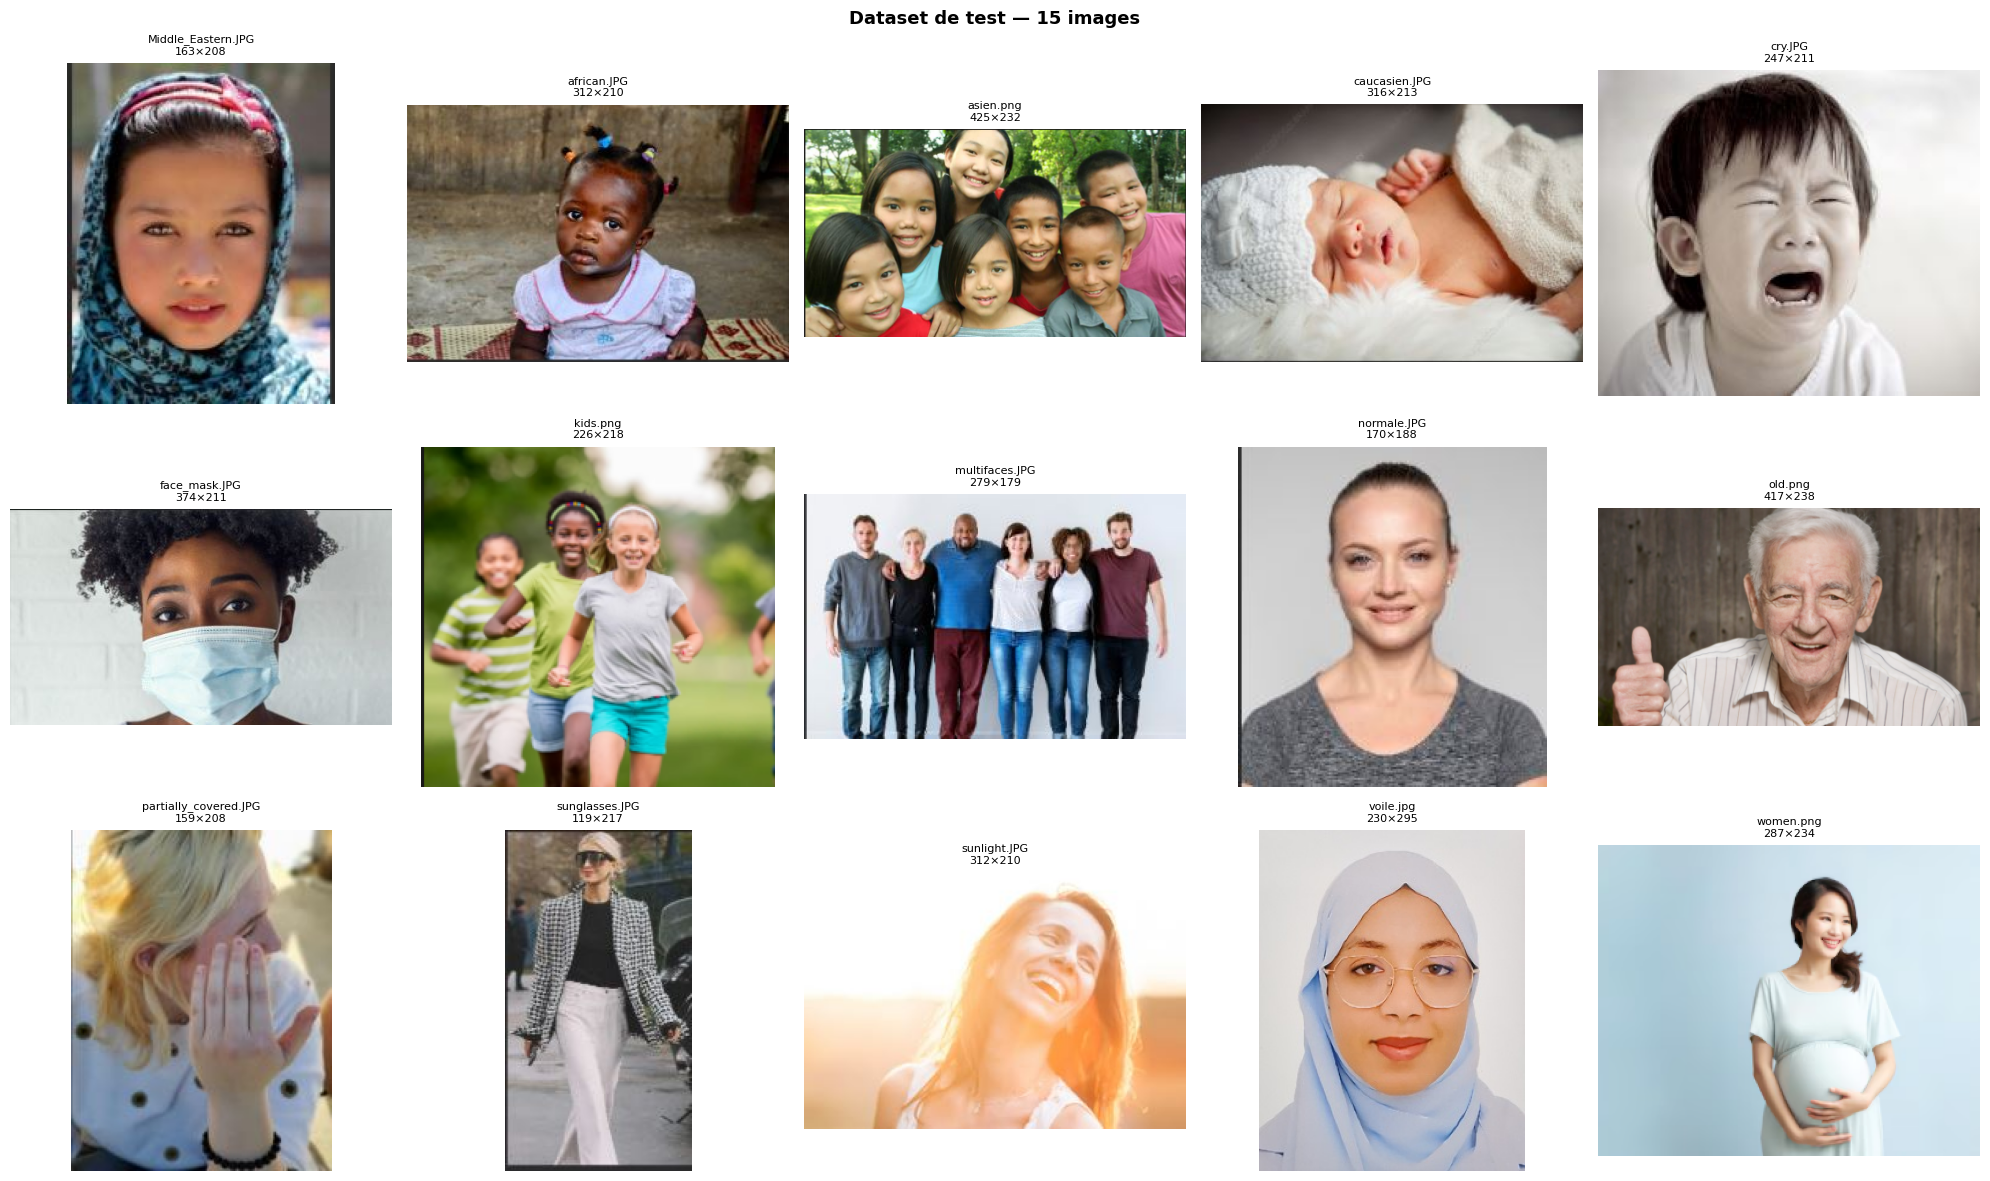

Aperçu sauvegardé ✅


In [6]:
# ==============================
# APERÇU DES IMAGES
# ==============================
n     = len(test_paths)
n_col = min(5, n)
n_row = (n + n_col - 1) // n_col

fig, axes = plt.subplots(n_row, n_col,
                          figsize=(4 * n_col, 4 * n_row))
fig.suptitle(f"Dataset de test — {n} images",
             fontsize=13, fontweight="bold")

# Aplatir axes
if n_row == 1 and n_col == 1:
    axes = [[axes]]
elif n_row == 1:
    axes = [list(axes)]
else:
    axes = [list(row) for row in axes]
flat_axes = [ax for row in axes for ax in row]

for i, ax in enumerate(flat_axes):
    if i < len(test_paths):
        img = cv2.imread(test_paths[i])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            h, w    = img.shape[:2]
            ax.imshow(img_rgb)
            ax.set_title(f"{os.path.basename(test_paths[i])}\n{w}×{h}",
                         fontsize=8)
        else:
            ax.set_title("Erreur lecture", fontsize=8, color="red")
    ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/results_mtcnn/00_dataset_overview.png",
            dpi=100, bbox_inches="tight")
plt.show()
print("Aperçu sauvegardé ✅")

# 5. Initialisation MTCNN

In [7]:
# ==============================
# INITIALISATION MTCNN
# ==============================
from mtcnn import MTCNN

mtcnn_model = MTCNN()

print("MTCNN initialisé ✅")
print("Architecture : 3 réseaux en cascade (PNet → RNet → ONet)")
print("Landmarks    : 5 points (yeux, nez, coins bouche)")
print("Entrée       : image RGB numpy array")

2026-05-28 14:25:27.129131: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779978327.317043      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779978327.373702      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779978327.834019      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779978327.834057      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779978327.834061      57 computation_placer.cc:177] computation placer alr

MTCNN initialisé ✅
Architecture : 3 réseaux en cascade (PNet → RNet → ONet)
Landmarks    : 5 points (yeux, nez, coins bouche)
Entrée       : image RGB numpy array


# 6. Fonction de detection MTCNN

In [8]:
# ==============================
# FONCTION DE DÉTECTION MTCNN
# ==============================
def detect_mtcnn(image_path, conf_threshold=0.90):
    """
    Détecte les visages dans une image avec MTCNN.

    Paramètres
    ----------
    image_path     : chemin vers l'image
    conf_threshold : seuil de confiance minimum (défaut 0.90)

    Retourne
    --------
    boxes     : liste de [x1, y1, x2, y2]
    landmarks : liste de 5 points [[x,y], ...]
    time_ms   : temps d'inférence en millisecondes
    n_faces   : nombre de visages détectés
    """
    # Lecture image en RGB (MTCNN attend du RGB)
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        print(f"  ⚠️  Impossible de lire : {image_path}")
        return [], [], 0.0, 0

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w    = img_rgb.shape[:2]

    # Inférence avec mesure du temps
    t0    = time.perf_counter()
    faces = mtcnn_model.detect_faces(img_rgb)
    t1    = time.perf_counter()

    elapsed_ms = (t1 - t0) * 1000

    boxes = []
    lmks  = []

    for face in faces:
        # Filtrer par confiance
        if face["confidence"] < conf_threshold:
            continue

        # Boîte englobante : MTCNN retourne [x, y, w, h]
        x, y, bw, bh = face["box"]
        x1 = max(0, x)
        y1 = max(0, y)
        x2 = min(w, x + bw)
        y2 = min(h, y + bh)
        boxes.append([x1, y1, x2, y2])

        # Landmarks : 5 points faciaux
        kp = face["keypoints"]
        lmks.append([
            list(kp["right_eye"]),
            list(kp["left_eye"]),
            list(kp["nose"]),
            list(kp["mouth_right"]),
            list(kp["mouth_left"]),
        ])

    return boxes, lmks, elapsed_ms, len(boxes)


# Test rapide sur la première image
boxes, lmks, ms, n = detect_mtcnn(test_paths[0])
print(f"Test rapide sur {os.path.basename(test_paths[0])} :")
print(f"  Visages détectés : {n}")
print(f"  Temps            : {ms:.1f} ms")
if boxes:
    print(f"  Première bbox    : {boxes[0]}")
    print(f"  Landmarks[0]     : {lmks[0]}")

Test rapide sur Middle_Eastern.JPG :
  Visages détectés : 1
  Temps            : 292.5 ms
  Première bbox    : [30, 44, 123, 179]
  Landmarks[0]     : [[np.int64(100), np.int64(101)], [np.int64(57), np.int64(102)], [np.int64(80), np.int64(132)], [np.int64(95), np.int64(146)], [np.int64(62), np.int64(147)]]


# 7. Détection sur toutes les images 

In [9]:
# ==============================
# DÉTECTION SUR TOUTES LES IMAGES
# ==============================
print("=" * 60)
print("  MTCNN — DÉTECTION SUR TOUTES LES IMAGES")
print("=" * 60)

results_mtcnn = []

for path in test_paths:
    boxes, lmks, ms, n = detect_mtcnn(path)

    results_mtcnn.append({
        "image"     : os.path.basename(path),
        "filepath"  : path,
        "n_faces"   : n,
        "time_ms"   : round(ms, 2),
        "boxes"     : boxes,
        "landmarks" : lmks,
        "detected"  : n > 0,
    })

    status = "✅" if n > 0 else "❌"
    print(f"  {status}  {os.path.basename(path):40s} "
          f"→ {n} visage(s)  |  {ms:.1f} ms")

# Statistiques globales
times   = [r["time_ms"] for r in results_mtcnn]
n_ok    = sum(1 for r in results_mtcnn if r["detected"])
n_miss  = sum(1 for r in results_mtcnn if not r["detected"])
fps_est = round(1000 / np.mean(times), 1)

print(f"\n{'='*60}")
print(f"  RÉSUMÉ MTCNN")
print(f"{'='*60}")
print(f"  Images testées       : {len(test_paths)}")
print(f"  Détections réussies  : {n_ok}")
print(f"  Images manquées      : {n_miss}")
print(f"  Temps moyen          : {np.mean(times):.1f} ms")
print(f"  Temps médian         : {np.median(times):.1f} ms")
print(f"  Temps min / max      : {np.min(times):.1f} / {np.max(times):.1f} ms")
print(f"  FPS estimé           : {fps_est}")
print(f"  Landmarks fournis    : Oui (5 points)")

  MTCNN — DÉTECTION SUR TOUTES LES IMAGES
  ✅  Middle_Eastern.JPG                       → 1 visage(s)  |  140.0 ms
  ✅  african.JPG                              → 1 visage(s)  |  167.9 ms
  ✅  asien.png                                → 7 visage(s)  |  199.5 ms
  ❌  caucasien.JPG                            → 0 visage(s)  |  151.5 ms
  ✅  cry.JPG                                  → 1 visage(s)  |  147.6 ms
  ✅  face_mask.JPG                            → 1 visage(s)  |  147.9 ms
  ✅  kids.png                                 → 3 visage(s)  |  152.1 ms
  ✅  multifaces.JPG                           → 6 visage(s)  |  154.5 ms
  ✅  normale.JPG                              → 1 visage(s)  |  134.0 ms
  ✅  old.png                                  → 1 visage(s)  |  174.8 ms
  ❌  partially_covered.JPG                    → 0 visage(s)  |  134.9 ms
  ✅  sunglasses.JPG                           → 1 visage(s)  |  123.5 ms
  ✅  sunlight.JPG                             → 1 visage(s)  |  139.4 ms
  ✅  voil

# 8. Visualisation des détections

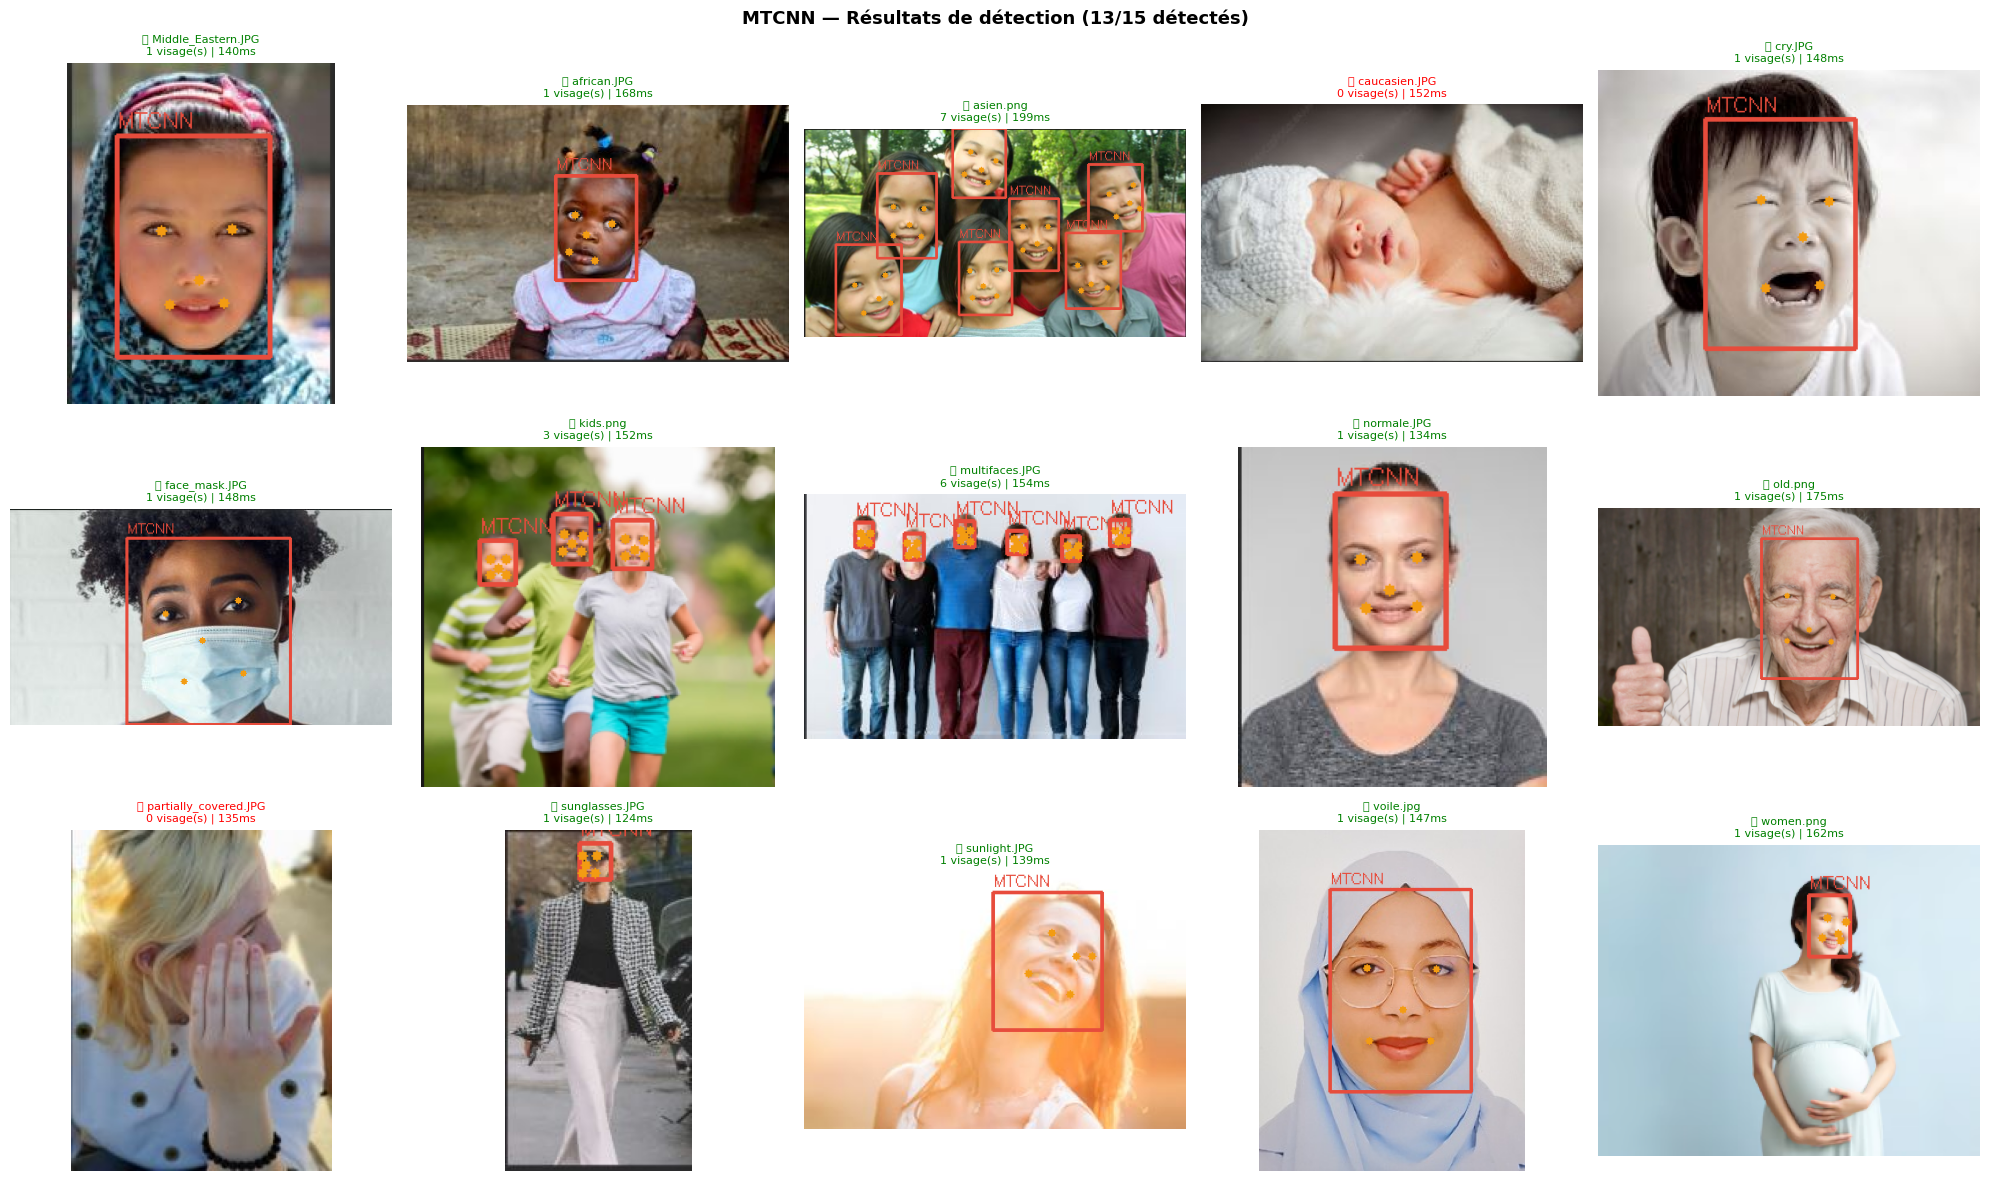

Visualisation sauvegardée ✅


In [10]:
# ==============================
# VISUALISATION DES DÉTECTIONS
# ==============================
COLOR_BOX = (231, 76,  60)    # rouge MTCNN
COLOR_LMK = (243, 156, 18)    # orange landmarks

def draw_mtcnn_result(result):
    """
    Dessine les bboxes et landmarks sur l'image.
    Retourne l'image annotée en RGB.
    """
    img = cv2.imread(result["filepath"])
    if img is None:
        return np.zeros((200, 200, 3), dtype=np.uint8)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    for i, box in enumerate(result["boxes"]):
        x1, y1, x2, y2 = [int(v) for v in box]

        # Boîte englobante
        cv2.rectangle(img, (x1, y1), (x2, y2), COLOR_BOX, 2)

        # Label confiance (non disponible ici car filtré avant)
        cv2.putText(img, "MTCNN", (x1, max(y1-5, 0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, COLOR_BOX, 1)

        # Landmarks
        if i < len(result["landmarks"]):
            for pt in result["landmarks"][i]:
                px, py = int(pt[0]), int(pt[1])
                cv2.circle(img, (px, py), 3, COLOR_LMK, -1)

    return img


n     = len(results_mtcnn)
n_col = min(5, n)
n_row = (n + n_col - 1) // n_col

fig, axes = plt.subplots(n_row, n_col,
                          figsize=(4 * n_col, 4 * n_row))
fig.suptitle(
    f"MTCNN — Résultats de détection "
    f"({sum(r['detected'] for r in results_mtcnn)}/{n} détectés)",
    fontsize=13, fontweight="bold"
)

if n_row == 1 and n_col == 1:
    axes = [[axes]]
elif n_row == 1:
    axes = [list(axes)]
else:
    axes = [list(row) for row in axes]
flat_axes = [ax for row in axes for ax in row]

for i, ax in enumerate(flat_axes):
    if i < len(results_mtcnn):
        r       = results_mtcnn[i]
        img_viz = draw_mtcnn_result(r)
        ax.imshow(img_viz)
        color   = "green" if r["detected"] else "red"
        status  = "✅" if r["detected"] else "❌"
        ax.set_title(
            f"{status} {r['image']}\n"
            f"{r['n_faces']} visage(s) | {r['time_ms']:.0f}ms",
            fontsize=8, color=color
        )
    ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/results_mtcnn/01_detections.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("Visualisation sauvegardée ✅")

# 9. Graphique des performances

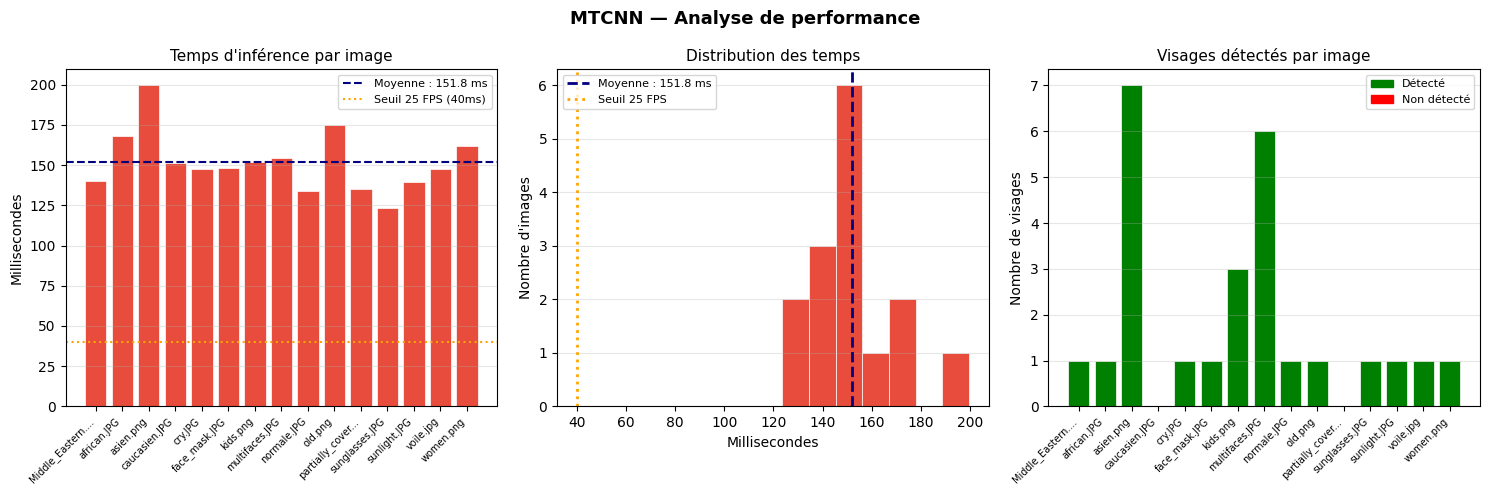

Graphiques de performance sauvegardés ✅


In [11]:
# ==============================
# GRAPHIQUES DE PERFORMANCE MTCNN
# ==============================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("MTCNN — Analyse de performance",
             fontsize=13, fontweight="bold")

COLOR = "#E74C3C"

# Graphique 1 : Temps par image
image_names = [r["image"][:15] + "..." if len(r["image"]) > 15
               else r["image"] for r in results_mtcnn]
times_per_img = [r["time_ms"] for r in results_mtcnn]

bars = axes[0].bar(range(len(image_names)), times_per_img,
                   color=COLOR, edgecolor="white", linewidth=0.5)
axes[0].axhline(y=np.mean(times_per_img), color="navy",
                linestyle="--", linewidth=1.5,
                label=f"Moyenne : {np.mean(times_per_img):.1f} ms")
axes[0].axhline(y=40, color="orange", linestyle=":",
                linewidth=1.5, label="Seuil 25 FPS (40ms)")
axes[0].set_xticks(range(len(image_names)))
axes[0].set_xticklabels(image_names, rotation=45, ha="right", fontsize=7)
axes[0].set_title("Temps d'inférence par image", fontsize=11)
axes[0].set_ylabel("Millisecondes")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

# Graphique 2 : Distribution des temps
axes[1].hist(times_per_img, bins=max(5, len(times_per_img)//2),
             color=COLOR, edgecolor="white", linewidth=0.5)
axes[1].axvline(x=np.mean(times_per_img), color="navy",
                linestyle="--", linewidth=2,
                label=f"Moyenne : {np.mean(times_per_img):.1f} ms")
axes[1].axvline(x=40, color="orange", linestyle=":",
                linewidth=2, label="Seuil 25 FPS")
axes[1].set_title("Distribution des temps", fontsize=11)
axes[1].set_xlabel("Millisecondes")
axes[1].set_ylabel("Nombre d'images")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.3)

# Graphique 3 : Nombre de visages détectés
n_faces_per_img = [r["n_faces"] for r in results_mtcnn]
colors_bar = ["green" if n > 0 else "red" for n in n_faces_per_img]
axes[2].bar(range(len(image_names)), n_faces_per_img,
            color=colors_bar, edgecolor="white", linewidth=0.5)
axes[2].set_xticks(range(len(image_names)))
axes[2].set_xticklabels(image_names, rotation=45, ha="right", fontsize=7)
axes[2].set_title("Visages détectés par image", fontsize=11)
axes[2].set_ylabel("Nombre de visages")
axes[2].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[2].grid(axis="y", alpha=0.3)

# Légende couleurs
from matplotlib.patches import Patch
legend = [Patch(color="green", label="Détecté"),
          Patch(color="red",   label="Non détecté")]
axes[2].legend(handles=legend, fontsize=8)

plt.tight_layout()
plt.savefig("/kaggle/working/results_mtcnn/02_performance.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("Graphiques de performance sauvegardés ✅")

# 10. Sauvegarde des resultats

In [12]:
# ==============================
# SAUVEGARDE DES RÉSULTATS MTCNN
# ==============================

# CSV des résultats (sans les boxes pour la lisibilité)
df_mtcnn = pd.DataFrame([{
    "image"    : r["image"],
    "n_faces"  : r["n_faces"],
    "time_ms"  : r["time_ms"],
    "detected" : r["detected"],
    "fps_eq"   : round(1000 / r["time_ms"], 1) if r["time_ms"] > 0 else 0,
} for r in results_mtcnn])

df_mtcnn.to_csv("/kaggle/working/results_mtcnn/mtcnn_results.csv", index=False)

# Résumé final
summary_mtcnn = {
    "detecteur"          : "MTCNN",
    "n_images"           : len(results_mtcnn),
    "n_detected"         : sum(r["detected"] for r in results_mtcnn),
    "n_missed"           : sum(not r["detected"] for r in results_mtcnn),
    "taux_detection"     : round(sum(r["detected"] for r in results_mtcnn) / len(results_mtcnn) * 100, 1),
    "time_mean_ms"       : round(np.mean([r["time_ms"] for r in results_mtcnn]), 1),
    "time_median_ms"     : round(np.median([r["time_ms"] for r in results_mtcnn]), 1),
    "time_min_ms"        : round(np.min([r["time_ms"] for r in results_mtcnn]), 1),
    "time_max_ms"        : round(np.max([r["time_ms"] for r in results_mtcnn]), 1),
    "fps_estime"         : round(1000 / np.mean([r["time_ms"] for r in results_mtcnn]), 1),
    "landmarks"          : True,
    "n_landmarks"        : 5,
}

print("=" * 60)
print("  RÉSUMÉ FINAL MTCNN")
print("=" * 60)
for k, v in summary_mtcnn.items():
    print(f"  {k:<25} : {v}")

print(f"\nFichiers sauvegardés dans /kaggle/working/results_mtcnn/")
for f in sorted(os.listdir("/kaggle/working/results_mtcnn/")):
    print(f"  {f}")

  RÉSUMÉ FINAL MTCNN
  detecteur                 : MTCNN
  n_images                  : 15
  n_detected                : 13
  n_missed                  : 2
  taux_detection            : 86.7
  time_mean_ms              : 151.8
  time_median_ms            : 147.9
  time_min_ms               : 123.5
  time_max_ms               : 199.5
  fps_estime                : 6.6
  landmarks                 : True
  n_landmarks               : 5

Fichiers sauvegardés dans /kaggle/working/results_mtcnn/
  00_dataset_overview.png
  01_detections.png
  02_performance.png
  mtcnn_results.csv
